# Predicting Online Shoppers’ Purchase Intention

**Assignment 1 — End-to-End Machine Learning Pipeline**  
Track A: scikit-learn | Binary classification | Random seed: 42

## Problem and motivation
Predict whether a session ends in a purchase (`Revenue`) from session browsing behavior and context. The potential use is to prioritize relevant assistance. False positives waste interventions; false negatives miss opportunities. Since purchases are the minority class, accuracy alone is not an adequate metric. This is predictive association, not causal inference.

## Dataset and source
UCI Online Shoppers Purchasing Intention Dataset: 12,330 sessions, 17 predictors, and a binary target. Inputs include page counts and durations, bounce/exit rates, page value, special-day proximity, device/browser/region/traffic categories, visitor type, month, and weekend. UCI reports 10,422 non-purchase sessions and 1,908 purchase sessions, with no missing values. Sakar, C. & Kastro, Y. (2018), UCI Machine Learning Repository, DOI: 10.24432/C5F88Q, CC BY 4.0. Source: https://archive.ics.uci.edu/dataset/468/online%2Bshoppers%2Bpurchasing%2Bintention%2Bdataset.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
    recall_score, f1_score, accuracy_score, confusion_matrix, classification_report,
    PrecisionRecallDisplay, RocCurveDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

RANDOM_STATE = 42
DATA_PATH = Path('data/online_shoppers_intention.csv')
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape, '| Missing cells:', int(df.isna().sum().sum()),
      '| Exact duplicate rows:', int(df.duplicated().sum()))
display(df.head())

Shape: (12330, 18) | Missing cells: 0 | Exact duplicate rows: 125


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## EDA
We inspect class balance, numeric ranges, skew, and group purchase rates. Extreme durations/counts are retained because they may be valid sessions. `PageValues` is excluded from the predictive features because UCI’s definition may make it an outcome proxy.


Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64


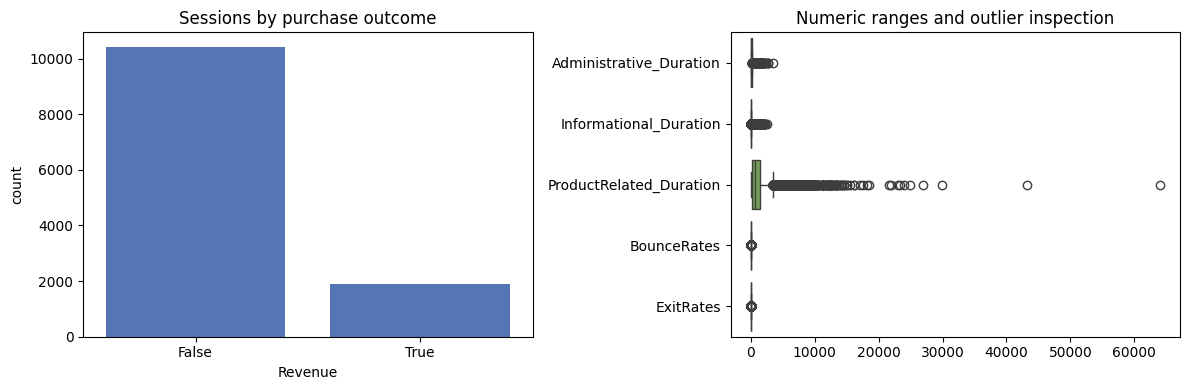

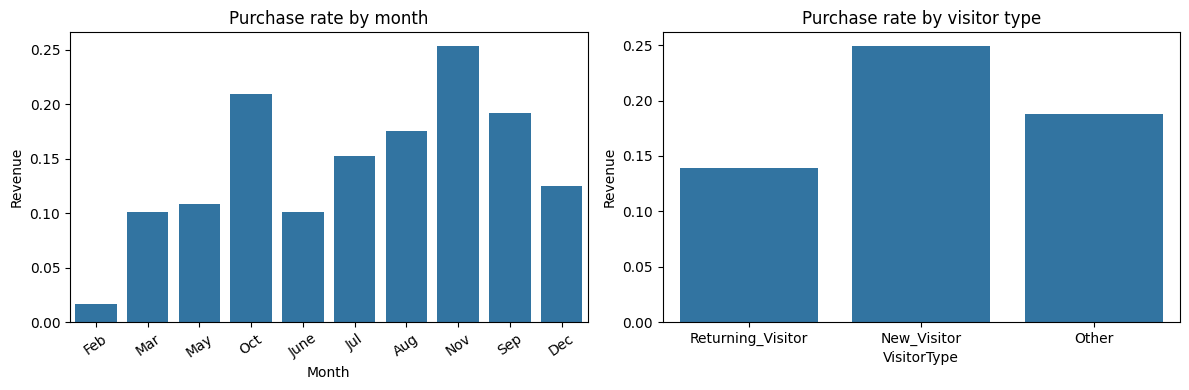

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.32,3.32,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12330.0,80.82,176.78,0.0,0.00,7.50,93.26,3398.75
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52
BounceRates,12330.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76
SpecialDay,12330.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


In [2]:
print(df['Revenue'].value_counts())
print((100 * df['Revenue'].value_counts(normalize=True)).round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='Revenue', ax=axes[0], color='#4472C4')
axes[0].set_title('Sessions by purchase outcome')
cols = ['Administrative_Duration','Informational_Duration','ProductRelated_Duration','BounceRates','ExitRates']
sns.boxplot(data=df[cols], orient='h', ax=axes[1], color='#70AD47')
axes[1].set_title('Numeric ranges and outlier inspection')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=df, x='Month', y='Revenue', errorbar=None, ax=axes[0])
axes[0].tick_params(axis='x', rotation=35); axes[0].set_title('Purchase rate by month')
sns.barplot(data=df, x='VisitorType', y='Revenue', errorbar=None, ax=axes[1])
axes[1].set_title('Purchase rate by visitor type')
plt.tight_layout(); plt.show()
display(df.select_dtypes('number').describe().T.round(2))

## Cleaning and feature engineering
UCI reports no missing values, which is verified above. Exact duplicates are counted and retained pending confirmation that identical rows do not represent duplicate sessions. Build total pages, total duration, and product time per page. Log-transform highly skewed nonnegative counts/durations; leave bounded rates on their original scale. Imputation remains in the pipeline as a robust safeguard. Use a stratified 80/20 split. All preprocessing is fit inside each CV fold to avoid leakage. Class weights address imbalance.


In [3]:
data = df.copy()
data['Weekend'] = data['Weekend'].astype(str)
data['Revenue'] = data['Revenue'].astype(bool).astype(int)
data['TotalPages'] = data[['Administrative','Informational','ProductRelated']].sum(axis=1)
data['TotalDuration'] = data[['Administrative_Duration','Informational_Duration','ProductRelated_Duration']].sum(axis=1)
data['ProductTimePerPage'] = data['ProductRelated_Duration'] / data['ProductRelated'].replace(0, np.nan)
for col in ['Administrative','Administrative_Duration','Informational','Informational_Duration',
            'ProductRelated','ProductRelated_Duration','TotalPages','TotalDuration','ProductTimePerPage']:
    data[col] = np.log1p(data[col].clip(lower=0))
X = data.drop(columns=['Revenue','PageValues'])
y = data['Revenue']
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, 'Test:', X_test.shape,
      '| positive rates:', round(y_train.mean(),3), round(y_test.mean(),3))
num_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
cat_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                     ('onehot', OneHotEncoder(handle_unknown='ignore'))])
preprocess = ColumnTransformer([('num', num_pipe, num_cols), ('cat', cat_pipe, cat_cols)])

Train: (9864, 19) Test: (2466, 19) | positive rates: 0.155 0.155


## Models, cross-validation, and tuning
Compare four algorithms with shuffled five-fold stratified CV. Grid search selects by average precision (AP), which emphasizes performance on the minority purchase class. The test set remains untouched during tuning and model selection.


In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
model_grids = {
 'Logistic Regression': (LogisticRegression(class_weight='balanced', solver='liblinear', max_iter=2000, random_state=RANDOM_STATE),
                         {'model__C':[0.01,0.1,1.0]}),
 'Decision Tree': (DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
                   {'model__max_depth':[4,8,None], 'model__min_samples_leaf':[5,20]}),
 'Random Forest': (RandomForestClassifier(class_weight='balanced_subsample', n_estimators=250, n_jobs=-1, random_state=RANDOM_STATE),
                   {'model__max_depth':[None,16], 'model__min_samples_leaf':[2,8], 'model__max_features':['sqrt']}),
 'Extra Trees': (ExtraTreesClassifier(class_weight='balanced', n_estimators=250, n_jobs=-1, random_state=RANDOM_STATE),
                 {'model__max_depth':[None,16], 'model__min_samples_leaf':[2,8], 'model__max_features':['sqrt']})}
searches = {}
for name, (model, grid) in model_grids.items():
    pipe = Pipeline([('prep', preprocess), ('model', model)])
    search = GridSearchCV(pipe, grid, scoring='average_precision', cv=cv, n_jobs=-1, refit=True, error_score='raise')
    search.fit(X_train, y_train)
    searches[name] = search
    print(name, 'CV AP:', round(search.best_score_,4), 'best:', search.best_params_)

/Users/abhisjh2/Documents/Github/ml-assignment-1st-sem/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/abhisjh2/Documents/Github/ml-assignment-1st-sem/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/abhisjh2/Documents/Github/ml-assignment-1st-sem/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/abhisjh2/Documents/Github/ml-assignment-1st-sem/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/abhisjh2/Documents/Github/ml-assignment-1st-sem/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/abhisjh2/Documents/Github/ml-assignment-1st-sem/.venv/lib/python3.9/site-pac

Logistic Regression CV AP: 0.3331 best: {'model__C': 0.01}


Decision Tree CV AP: 0.3218 best: {'model__max_depth': 8, 'model__min_samples_leaf': 20}


Random Forest CV AP: 0.3849 best: {'model__max_depth': 16, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 8}


Extra Trees CV AP: 0.3827 best: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 8}


In [5]:
rows = []
for name, search in searches.items():
    pred = search.best_estimator_.predict(X_test)
    score = search.best_estimator_.predict_proba(X_test)[:,1]
    rows.append({'Model':name, 'CV AP':search.best_score_, 'Test AP':average_precision_score(y_test,score),
        'Test ROC-AUC':roc_auc_score(y_test,score), 'Test Precision':precision_score(y_test,pred,zero_division=0),
        'Test Recall':recall_score(y_test,pred,zero_division=0), 'Test F1':f1_score(y_test,pred,zero_division=0),
        'Test Accuracy':accuracy_score(y_test,pred)})
results = pd.DataFrame(rows).sort_values('Test AP', ascending=False).reset_index(drop=True)
display(results.round(3))
Path('output').mkdir(exist_ok=True)
results.to_csv('output/model_comparison.csv', index=False)

/Users/abhisjh2/Documents/Github/ml-assignment-1st-sem/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/abhisjh2/Documents/Github/ml-assignment-1st-sem/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/abhisjh2/Documents/Github/ml-assignment-1st-sem/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/abhisjh2/Documents/Github/ml-assignment-1st-sem/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/abhisjh2/Documents/Github/ml-assignment-1st-sem/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/abhisjh2/Documents/Github/ml-assignment-1st-sem/.venv/lib/python3.9/site-pac

,Model,CV AP,Test AP,Test ROC-AUC,Test Precision,Test Recall,Test F1,Test Accuracy
0,Extra Trees,0.383,0.363,0.770,0.294,0.652,0.405,0.703
1,Random Forest,0.385,0.357,0.766,0.323,0.461,0.380,0.767
2,Logistic Regression,0.333,0.314,0.736,0.250,0.749,0.375,0.614
3,Decision Tree,0.322,0.296,0.710,0.232,0.688,0.347,0.598


## Evaluation and discussion
Select the final model by the best mean CV AP, not by test performance. Report AP, ROC-AUC, purchase precision/recall/F1, accuracy, confusion matrix, and curves. The default 0.5 threshold is illustrative; choose an operating threshold only after specifying intervention costs.


Selected by CV AP: Random Forest
              precision    recall  f1-score   support

 No purchase       0.89      0.82      0.86      2084
    Purchase       0.32      0.46      0.38       382

    accuracy                           0.77      2466
   macro avg       0.61      0.64      0.62      2466
weighted avg       0.80      0.77      0.78      2466

Confusion matrix: [[1715  369]
 [ 206  176]]


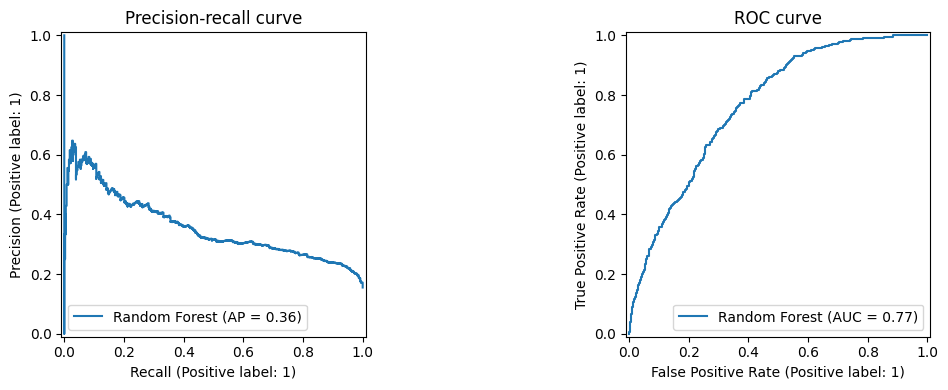

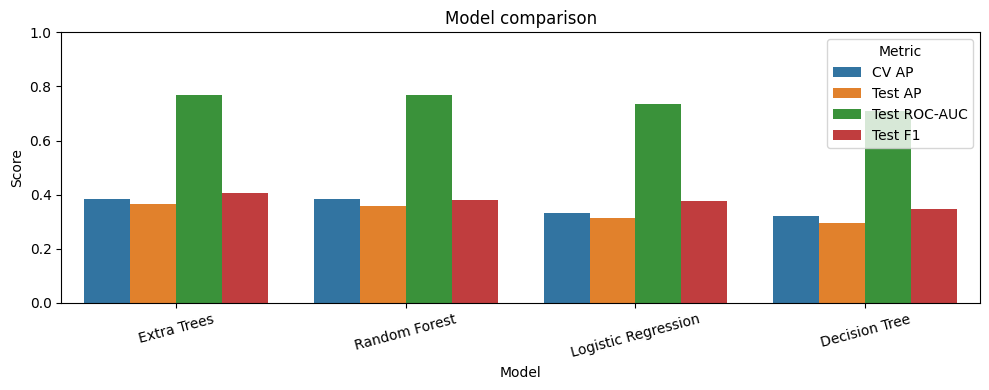

In [6]:
best_name = max(searches, key=lambda name: searches[name].best_score_)
best = searches[best_name].best_estimator_
y_pred = best.predict(X_test)
y_score = best.predict_proba(X_test)[:,1]
print('Selected by CV AP:', best_name)
print(classification_report(y_test, y_pred, target_names=['No purchase','Purchase'], zero_division=0))
print('Confusion matrix:', confusion_matrix(y_test, y_pred))
fig, axes = plt.subplots(1,2,figsize=(12,4))
PrecisionRecallDisplay.from_estimator(best, X_test, y_test, ax=axes[0], name=best_name)
RocCurveDisplay.from_estimator(best, X_test, y_test, ax=axes[1], name=best_name)
axes[0].set_title('Precision-recall curve'); axes[1].set_title('ROC curve')
plt.tight_layout(); plt.show()
plotdata = results.melt(id_vars='Model', value_vars=['CV AP','Test AP','Test ROC-AUC','Test F1'], var_name='Metric', value_name='Score')
plt.figure(figsize=(10,4)); sns.barplot(data=plotdata, x='Model', y='Score', hue='Metric')
plt.ylim(0,1); plt.xticks(rotation=15); plt.title('Model comparison'); plt.tight_layout(); plt.show()

## Limitations and future work
The dataset is older and from one source. A random stratified split does not simulate future-time performance. Session data omits price, product, campaign exposure, and consent context. Feature associations are not causal. Validate on recent time-separated data, test stability across groups, calibrate probabilities, choose a threshold from explicit costs, and review privacy/consent before any real use.

## Reproducibility
Run from the repository root with Python 3.9+ and `pip install -r requirements.txt`. Seed: 42. Raw UCI data and a sample are included under `data/`.
